# Human-in-the-Loop Email Drafting with LangGraph

This notebook demonstrates a review-and-revise workflow. LangGraph drafts an email, pauses for human feedback, updates the draft when requested, and reaches the send step only after approval.

The graph uses an in-memory checkpointer so the workflow can resume after each review response. The example simulates approval; it does not connect to an email service.

## 1. Set up the model and dependencies

These imports provide the graph, state model, language model, and in-memory checkpointer. Configure your model credentials in the environment or a local `.env` file; do not put API keys in notebook cells or commit them.

In [42]:
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from typing import Literal
load_dotenv()

True

## 2. Define the email state

`MailState` is the shared data carried through the graph. It holds the user's request, the current email draft, and the latest feedback. The draft node can therefore use the same original request and current draft each time the reviewer asks for a revision.

In [43]:
llm = ChatOpenAI(model="gpt-6-luna")

class MailState(BaseModel):
    user_requirement:str = Field(description="What email does user want to create", default="")
    email_draft:str = Field(description="First email generated or email updated with recursive user feedback gets stored here", default="")
    user_feedback:str = Field(description="What the user wants to change", default="")

## 3. Draft or revise the email

The `draft_email` node is a Python function that calls the language model. Its first prompt asks for a concise email that follows the user's constraints without inventing details. On later passes it includes the original request, the existing draft, and the new feedback so the model revises the email rather than starting from an unrelated scenario.

In [44]:
def draft_email(state: MailState) -> MailState:
    if state.user_feedback:
        prompt = f"""
            Revise the current email using the human's feedback.

            Original request:
            {state.user_requirement}

            Current draft:
            {state.email_draft}

            Human feedback:
            {state.user_feedback}

            Apply the feedback while preserving the request's intent and any
            length, audience, tone, or formatting requirements. Do not invent
            facts, commitments, or results. Return only the revised email body.
        """
    else:
        prompt = f"""
            Write an email that fulfills this request:
            {state.user_requirement}

            Make it clear, concise, and appropriate for the intended recipient.
            Follow the requested length and format. Do not invent facts or
            commitments. Return only the email body, without a subject line
            unless the request asks for one.
        """

    state.email_draft = llm.invoke(prompt).content
    return state

from langgraph.types import interrupt


def human_feedback(state: MailState) -> MailState:
    feedback = interrupt({
        "draft": state.email_draft,
        "instructions": (
            "Review the draft. Reply exactly 'approved', 'yes', or 'continue' "
            "to approve it for sending. Otherwise, describe the changes you "
            "want; the draft will be revised and shown to you again. The email "
            "will not be sent until you approve it."
        ),
    }).strip().lower()

    if feedback in ("approved", "yes", "continue"):
        state.user_feedback = ""
    else:
        state.user_feedback = feedback
    return state


def send_email(state: MailState) -> MailState:
    if not state.user_feedback:
        print("Email sent successfully")
        return state


def recursive_feedback_draft_generation(
    state: MailState,
) -> Literal["draft_email", "send_email"]:
    if state.user_feedback:
        return "draft_email"
    return "send_email"


### Pause for human review

`interrupt()` pauses graph execution and presents the current draft with instructions. Resume the same thread with `Command(resume=...)`. Approval is recognized only when the reply is `approved`, `yes`, or `continue` (case and surrounding whitespace are normalized); any other reply is treated as revision feedback. The graph loops back to drafting until approval, and only then reaches `send_email`.

## 4. Assemble, compile, and inspect the graph

The edges form this cycle: draft email ? human review ? revise and review again, or send after approval. The conditional router selects the next step based on whether `user_feedback` is present.

State is the data being processed; the checkpointer stores snapshots of that state. `InMemorySaver` enables this notebook to resume after an interrupt, but its checkpoints are temporary and disappear when the Python process exits. The `thread_id` used in each invocation identifies the same workflow instance.

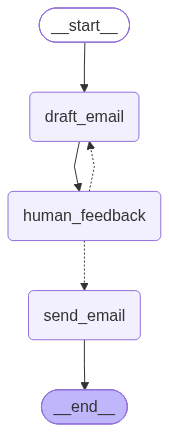

In [45]:
graph_core = StateGraph(MailState)
graph_core.add_node("draft_email", draft_email)
graph_core.add_node("human_feedback", human_feedback)
graph_core.add_node("send_email", send_email)

graph_core.add_edge(START, "draft_email")
graph_core.add_edge("draft_email", "human_feedback")
graph_core.add_conditional_edges("human_feedback", recursive_feedback_draft_generation)
graph_core.add_edge("send_email", END)

graph = graph_core.compile(checkpointer=InMemorySaver())

from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

## 5. Create the first draft

The request gives the model a specific recipient, proposal, format, and guardrails. The graph runs until it reaches the review interrupt, where the draft is available for approval or revision.

In [46]:
config = {"configurable": {"thread_id": 1}}
user_requirement = (
    "Write a concise, two-sentence email to my manager proposing a 30-day "
    "pilot at one phone-accessory store to reduce excess inventory. Recommend "
    "pairing slow-moving phone cases with popular chargers, and say we will "
    "review sell-through weekly. Do not include a subject line or claim "
    "guaranteed savings."
)
res = graph.invoke({"user_requirement": user_requirement}, config=config)
print(res["email_draft"])


Hi, I’d like to propose a 30-day pilot at one phone-accessory store to reduce excess inventory by pairing slow-moving phone cases with popular chargers. We can review sell-through weekly and assess the results at the end of the pilot.


## 6. Give focused feedback and inspect the revision

This feedback keeps the original purpose and two-sentence format, while adding a concrete success target and clarifying that it is a goal rather than a promise. Resuming with this text continues the interrupted graph on the same thread; the graph revises the email and pauses again for review.

In [47]:
from langgraph.types import Command

feedback = (
    "Keep the two-sentence limit and weekly sell-through review. Make the "
    "success measure more concrete by proposing a goal to reduce inventory "
    "older than 90 days by 15%, but phrase it as a target, not a guarantee."
)
res = graph.invoke(Command(resume=feedback), config=config)
print("Feedback:", res["user_feedback"])
print("\nRevised draft:")
print(res["email_draft"])


Feedback: keep the two-sentence limit and weekly sell-through review. make the success measure more concrete by proposing a goal to reduce inventory older than 90 days by 15%, but phrase it as a target, not a guarantee.

Revised draft:
Hi, I’d like to propose a 30-day pilot at one phone-accessory store to reduce excess inventory by pairing slow-moving phone cases with popular chargers. We can review sell-through weekly, with a target of reducing inventory older than 90 days by 15% over the pilot.


## 7. Approve the final draft

Once satisfied, resume the same thread with `approved`. The human-feedback node clears the pending revision feedback, so the router sends the approved draft to the final node. In a production application, that node would call an email provider; here it prints a simulated success message.

In [48]:
res = graph.invoke(Command(resume="approved"), config=config)
print("\nApproved email:")
print(res["email_draft"])


Email sent successfully

Approved email:
Hi, I’d like to propose a 30-day pilot at one phone-accessory store to reduce excess inventory by pairing slow-moving phone cases with popular chargers. We can review sell-through weekly, with a target of reducing inventory older than 90 days by 15% over the pilot.
